In [1]:
!pip install ctgan

In [2]:

import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE
from ctgan import CTGAN
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv("/content/FinalDataSet (1).csv")

In [4]:
print("Missing values:\n", data.isnull().sum())

Missing values:
 Age                     0
Gender                  0
Systolic BP (mmHg)      0
Diastolic BP (mmHg)     0
Body Temp               4
Pulse                   2
SPo2 (%)               82
 Air Temp               0
Humidity               16
Heat Index in C        16
RiskLabel               0
dtype: int64


In [5]:
for column in data.columns:
    if data[column].dtype == 'object':
        data[column].fillna(data[column].mode()[0], inplace=True)
    else:
        data[column].fillna(data[column].median(), inplace=True)

print("After filling missing values:\n", data.isnull().sum())


After filling missing values:
 Age                    0
Gender                 0
Systolic BP (mmHg)     0
Diastolic BP (mmHg)    0
Body Temp              0
Pulse                  0
SPo2 (%)               0
 Air Temp              0
Humidity               0
Heat Index in C        0
RiskLabel              0
dtype: int64


<ipython-input-5-08146884805b>:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[column].fillna(data[column].median(), inplace=True)
<ipython-input-5-08146884805b>:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

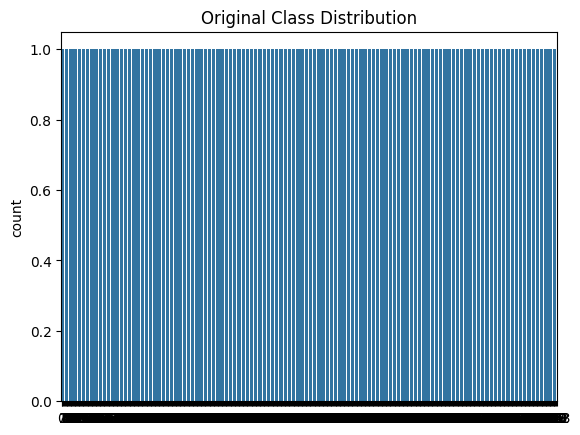

In [6]:
sns.countplot(data['RiskLabel'])
plt.title("Original Class Distribution")
plt.show()

In [7]:
print("Class distribution:\n", data['RiskLabel'].value_counts())


Class distribution:
 RiskLabel
0    369
1    138
2    107
Name: count, dtype: int64


In [8]:
data['Gender'] = data['Gender'].map({'Male': 0, 'Female': 1})

print(data['Gender'].head())


0    1
1    0
2    1
3    1
4    0
Name: Gender, dtype: int64


In [9]:
data.head()

,Age,Gender,Systolic BP (mmHg),Diastolic BP (mmHg),Body Temp,Pulse,SPo2 (%),Air Temp,Humidity,Heat Index in C,RiskLabel
0,55,1,70,40,104.0,110.0,99.0,34.1,73.0,49.0,2
1,50,0,130,80,99.7,78.0,95.0,26.3,81.0,28.0,0
2,70,1,90,50,98.4,90.0,95.0,34.5,74.0,51.0,1
3,60,1,110,70,99.0,78.0,99.0,28.4,89.0,35.0,0
4,26,0,130,96,103.0,102.0,99.0,35.7,57.0,46.0,2


In [10]:

X = data.drop('RiskLabel', axis=1)
y = data['RiskLabel']

smote = SMOTE(sampling_strategy='auto')
X_resampled, y_resampled = smote.fit_resample(X, y)


data_resampled = pd.concat([pd.DataFrame(X_resampled, columns=X.columns), pd.Series(y_resampled, name='RiskLabel')], axis=1)



In [11]:
print("Class distribution after SMOTE:\n", y_resampled.value_counts())

Class distribution after SMOTE:
 RiskLabel
2    369
0    369
1    369
Name: count, dtype: int64


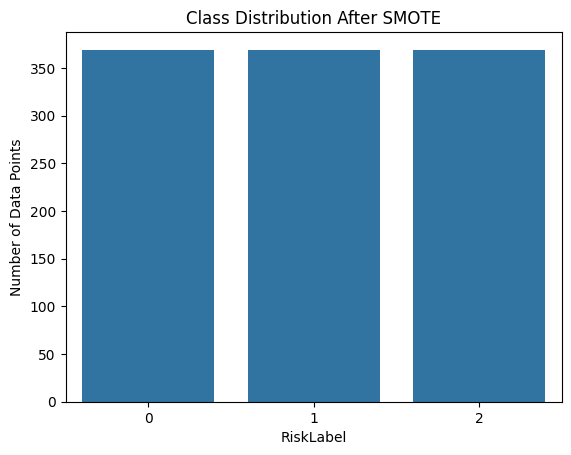

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='RiskLabel', data=data_resampled)
plt.title("Class Distribution After SMOTE")
plt.xlabel("RiskLabel")
plt.ylabel("Number of Data Points")
plt.show()


In [13]:

data_resampled.to_csv("smote_generated_data.csv", index=False)


In [14]:
import pandas as pd
from ctgan import CTGAN

data_resampled = pd.read_csv('/content/smote_generated_data.csv')


In [15]:
data_resampled.head()

,Age,Gender,Systolic BP (mmHg),Diastolic BP (mmHg),Body Temp,Pulse,SPo2 (%),Air Temp,Humidity,Heat Index in C,RiskLabel
0,55,1,70,40,104.0,110.0,99.0,34.1,73.0,49.0,2
1,50,0,130,80,99.7,78.0,95.0,26.3,81.0,28.0,0
2,70,1,90,50,98.4,90.0,95.0,34.5,74.0,51.0,1
3,60,1,110,70,99.0,78.0,99.0,28.4,89.0,35.0,0
4,26,0,130,96,103.0,102.0,99.0,35.7,57.0,46.0,2


In [16]:
data_resampled.drop(columns=['RiskLabel'])

,Age,Gender,Systolic BP (mmHg),Diastolic BP (mmHg),Body Temp,Pulse,SPo2 (%),Air Temp,Humidity,Heat Index in C
0,55,1,70,40,104.000000,110.000000,99.000000,34.100000,73.000000,49.000000
1,50,0,130,80,99.700000,78.000000,95.000000,26.300000,81.000000,28.000000
2,70,1,90,50,98.400000,90.000000,95.000000,34.500000,74.000000,51.000000
3,60,1,110,70,99.000000,78.000000,99.000000,28.400000,89.000000,35.000000
4,26,0,130,96,103.000000,102.000000,99.000000,35.700000,57.000000,46.000000
...,...,...,...,...,...,...,...,...,...,...
1102,21,1,99,69,103.123204,80.492814,95.184805,34.332238,79.677620,53.123204
1103,14,1,86,56,104.688715,85.509718,98.311285,33.549028,84.708151,53.132289
1104,40,0,100,60,105.000000,144.000000,96.000000,38.500000,57.000000,55.000000
1105,40,0,135,91,104.381516,123.815159,96.289095,35.144548,69.514229,50.381516


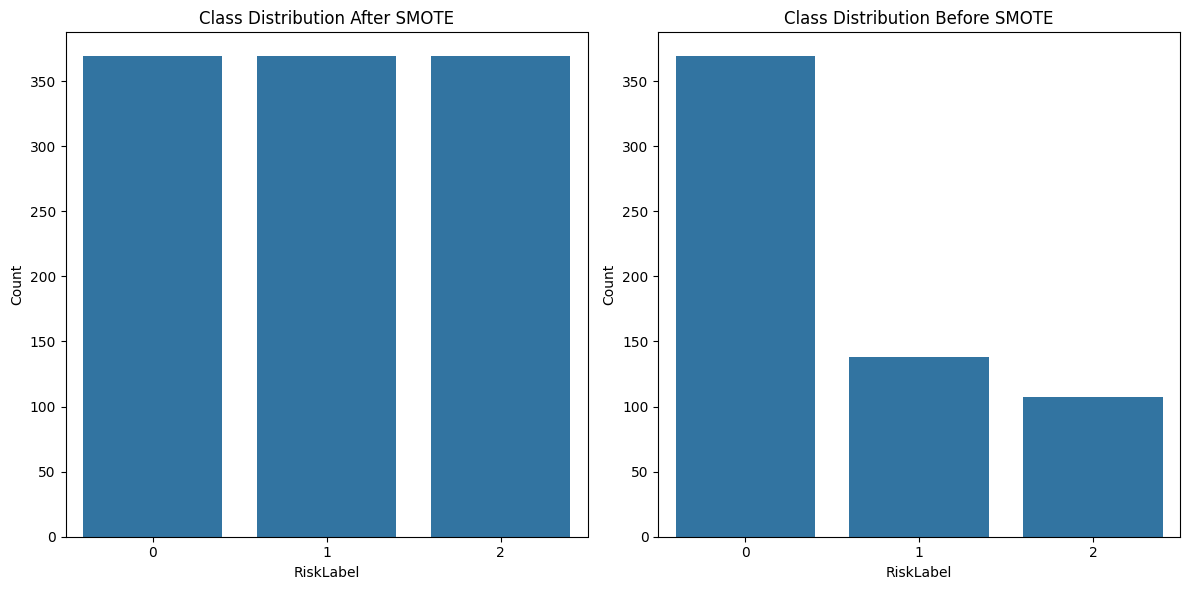

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
sns.countplot(x='RiskLabel', data=data_resampled)
plt.title('Class Distribution After SMOTE')
plt.xlabel('RiskLabel')
plt.ylabel('Count')


plt.subplot(1, 2, 2)
sns.countplot(x='RiskLabel', data=original_data)
plt.title('Class Distribution Before SMOTE')
plt.xlabel('RiskLabel')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


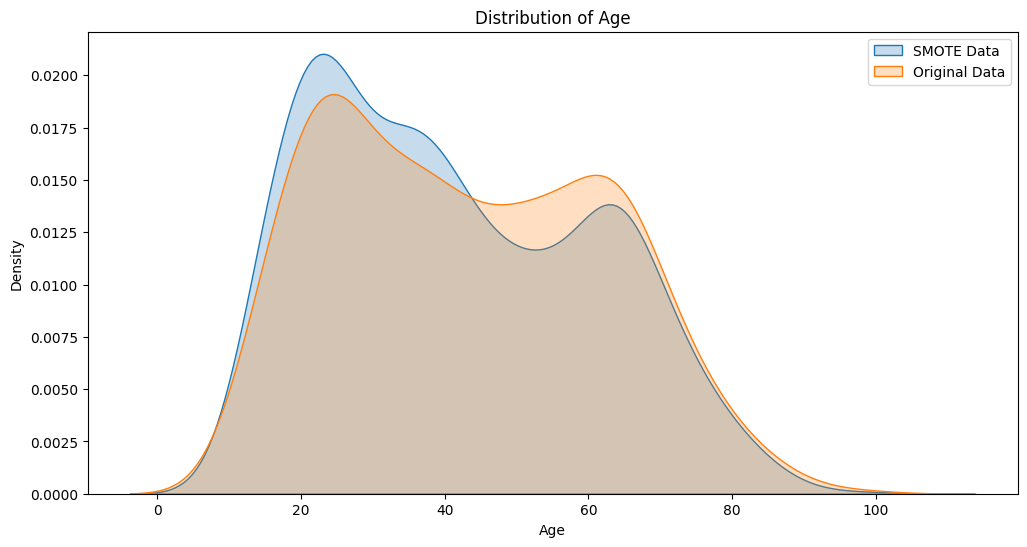

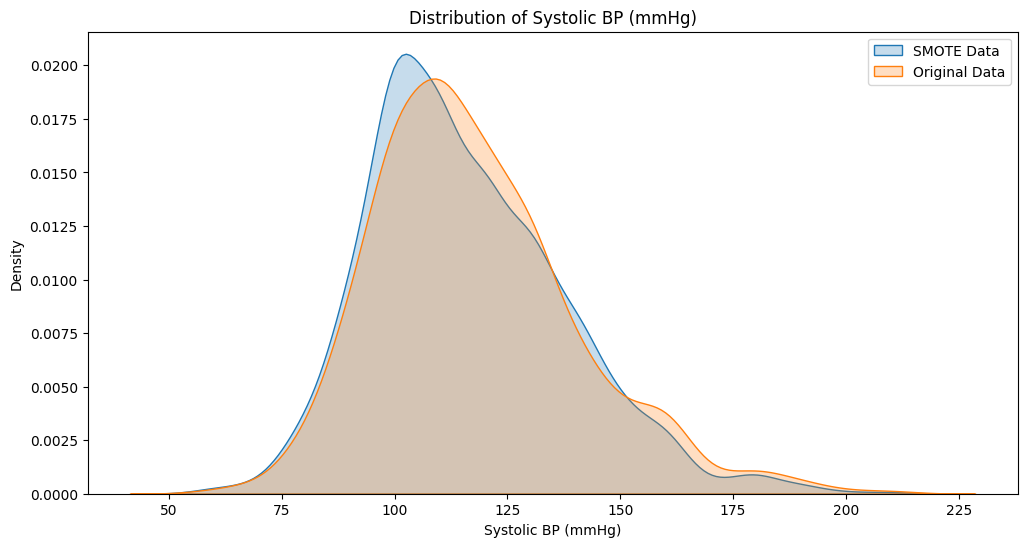

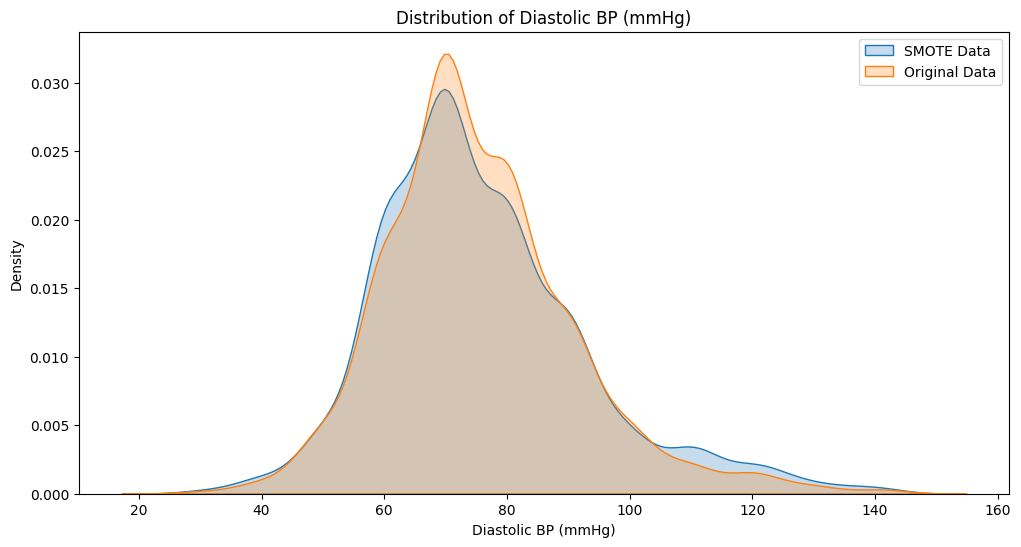

In [19]:
original_data = pd.read_csv('/content/FinalDataSet (1).csv')
features_to_compare = ['Age', 'Systolic BP (mmHg)', 'Diastolic BP (mmHg)']  # Add more features as needed

for feature in features_to_compare:
    plt.figure(figsize=(12, 6))

    sns.kdeplot(data_resampled[feature], label='SMOTE Data', fill=True)
    sns.kdeplot(original_data[feature], label='Original Data', fill=True)  # Replace original_data with your actual DataFrame

    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Density')
    plt.legend()
    plt.show()


In [22]:
# Convert 'Male' to 1 and 'Female' to 0 in the 'Gender' column
original_data['Gender'] = original_data['Gender'].replace({'Male': 1, 'Female': 0})

# Alternatively, you can use the map method
# original_data['Gender'] = original_data['Gender'].map({'Male': 1, 'Female': 0})

# Display the first few rows to verify the changes
print(original_data.head())


   Age  Gender  Systolic BP (mmHg)  Diastolic BP (mmHg)  Body Temp  Pulse  \
0   55       0                  70                   40      104.0  110.0   
1   50       1                 130                   80       99.7   78.0   
2   70       0                  90                   50       98.4   90.0   
3   60       0                 110                   70       99.0   78.0   
4   26       1                 130                   96      103.0  102.0   

   SPo2 (%)   Air Temp   Humidity   Heat Index in C  RiskLabel  
0      99.0        34.1       73.0             49.0          2  
1      95.0        26.3       81.0             28.0          0  
2      95.0        34.5       74.0             51.0          1  
3      99.0        28.4       89.0             35.0          0  
4      99.0        35.7       57.0             46.0          2  


<ipython-input-22-630f6ad95ba9>:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  original_data['Gender'] = original_data['Gender'].replace({'Male': 1, 'Female': 0})


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Split original data for training
X_original = original_data.drop(columns=['RiskLabel'])
y_original = original_data['RiskLabel']

X_train_orig, X_test_orig, y_train_orig, y_test_orig = train_test_split(X_original, y_original, test_size=0.2, random_state=42)

# Train on original data
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train_orig, y_train_orig)

# Predict and evaluate on original data
y_pred_orig = classifier.predict(X_test_orig)
print("Original Data Classification Report:\n", classification_report(y_test_orig, y_pred_orig))
print("Confusion Matrix:\n", confusion_matrix(y_test_orig, y_pred_orig))

# Split SMOTE data for training
X_resampled = data_resampled.drop(columns=['RiskLabel'])
y_resampled = data_resampled['RiskLabel']

X_train_res, X_test_res, y_train_res, y_test_res = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Train on SMOTE data
classifier.fit(X_train_res, y_train_res)

# Predict and evaluate on SMOTE data
y_pred_res = classifier.predict(X_test_res)
print("SMOTE Data Classification Report:\n", classification_report(y_test_res, y_pred_res))
print("Confusion Matrix:\n", confusion_matrix(y_test_res, y_pred_res))


Original Data Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.97      0.90        70
           1       0.87      0.59      0.70        34
           2       0.95      0.95      0.95        19

    accuracy                           0.86       123
   macro avg       0.89      0.84      0.85       123
weighted avg       0.86      0.86      0.85       123

Confusion Matrix:
 [[68  2  0]
 [13 20  1]
 [ 0  1 18]]
SMOTE Data Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.90      0.92        83
           1       0.89      0.90      0.90        72
           2       0.97      1.00      0.99        67

    accuracy                           0.93       222
   macro avg       0.93      0.94      0.93       222
weighted avg       0.93      0.93      0.93       222

Confusion Matrix:
 [[75  8  0]
 [ 5 65  2]
 [ 0  0 67]]


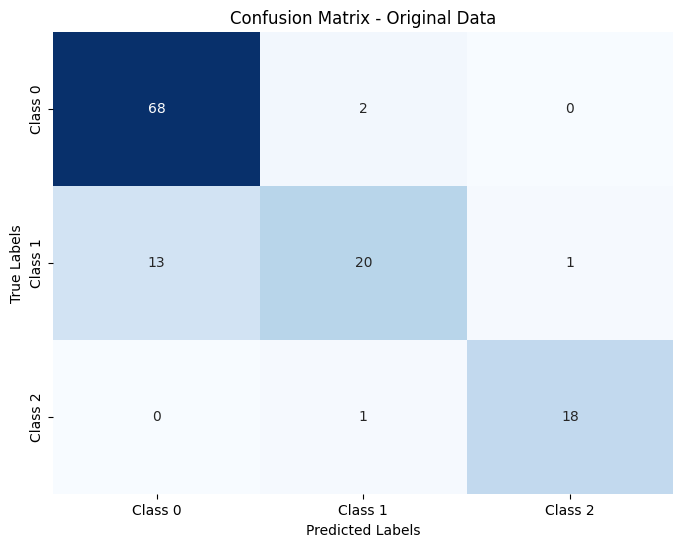

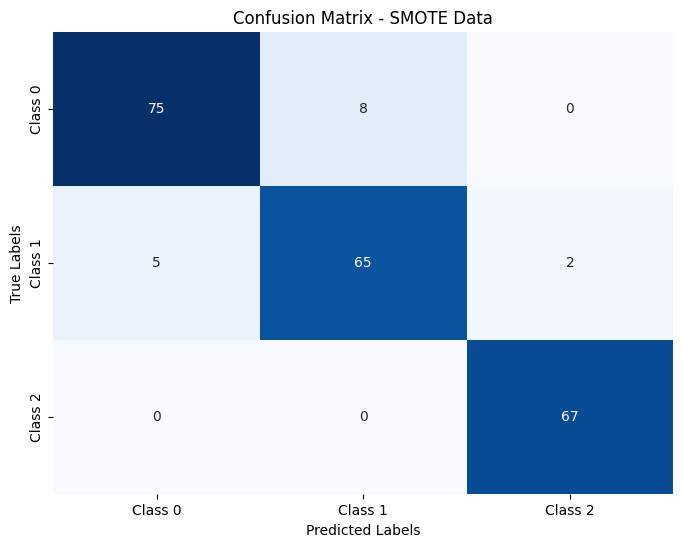

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_confusion_matrix(y_true, y_pred, title='Confusion Matrix'):

    cm = confusion_matrix(y_true, y_pred)


    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Class 0', 'Class 1', 'Class 2'],  # Adjust according to your classes
                yticklabels=['Class 0', 'Class 1', 'Class 2'])

    plt.title(title)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()


plot_confusion_matrix(y_test_orig, y_pred_orig, title='Confusion Matrix - Original Data')

plot_confusion_matrix(y_test_res, y_pred_res, title='Confusion Matrix - SMOTE Data')
